Document findings on robustness testing by generating a structured technical report, detailing experimental setups, performance trends, failure modes, and recommendations for improving model resilience.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target]).copy()

X = df[features]
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [2]:
model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        class_weight="balanced"
    )
)

model.fit(X_train, y_train)

baseline_pred = model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_f1 = f1_score(y_test, baseline_pred, zero_division=0)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline F1 Score:", round(baseline_f1, 4))

Baseline Accuracy: 0.75
Baseline F1 Score: 0.8333


In [3]:
rng = np.random.default_rng(42)
stds = X_train.std().replace(0, 1).to_numpy()
lower = X_train.min().to_numpy()
upper = X_train.max().to_numpy()

robustness_results = []

for level in [0, 0.05, 0.1, 0.2, 0.5, 1.0]:
    test_data = X_test.copy()

    noise = rng.normal(
        0, level, size=test_data.shape
    ) * stds

    test_data[features] = np.clip(
        test_data[features].to_numpy() + noise,
        lower,
        upper
    )

    pred = model.predict(test_data)

    robustness_results.append({
        "Perturbation Level": level,
        "Accuracy": accuracy_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "Changed Predictions": np.mean(pred != baseline_pred)
    })

robustness_df = pd.DataFrame(robustness_results)
print(robustness_df.round(4).to_string(index=False))

 Perturbation Level  Accuracy  F1 Score  Changed Predictions
               0.00    0.7500    0.8333               0.0000
               0.05    0.7500    0.8333               0.0000
               0.10    0.7500    0.8333               0.0000
               0.20    0.8125    0.8800               0.0625
               0.50    0.5625    0.7200               0.1875
               1.00    0.8125    0.8800               0.0625


In [4]:
shift_results = []

for feature in features:
    for shift in [0.5, 1.0, 2.0]:
        shifted = X_test.copy()
        shifted[feature] += shift * X_train[feature].std()

        pred = model.predict(shifted)

        shift_results.append({
            "Feature": feature,
            "Shift (Std)": shift,
            "Accuracy": accuracy_score(y_test, pred),
            "F1 Score": f1_score(y_test, pred, zero_division=0)
        })

shift_df = pd.DataFrame(shift_results)
print(shift_df.round(4).to_string(index=False))

 Feature  Shift (Std)  Accuracy  F1 Score
     age          0.5    0.6875    0.8148
     age          1.0    0.6875    0.8148
     age          2.0    0.6875    0.8148
trestbps          0.5    0.8125    0.8800
trestbps          1.0    0.7500    0.8462
trestbps          2.0    0.7500    0.8462
    chol          0.5    0.8125    0.8800
    chol          1.0    0.8125    0.8800
    chol          2.0    0.8125    0.8800
 thalach          0.5    0.8125    0.8800
 thalach          1.0    0.8125    0.8800
 thalach          2.0    0.8125    0.8800
 oldpeak          0.5    0.7500    0.8333
 oldpeak          1.0    0.7500    0.8333
 oldpeak          2.0    0.7500    0.8333


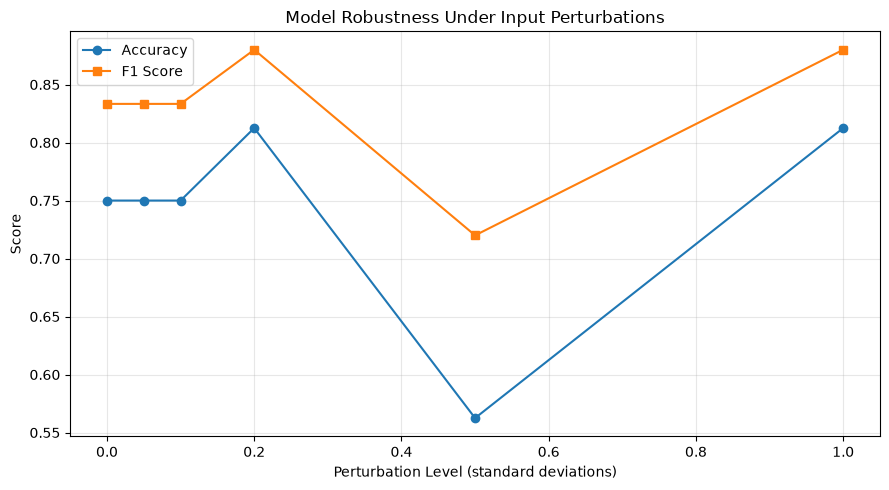

In [5]:
plt.figure(figsize=(9, 5))

plt.plot(
    robustness_df["Perturbation Level"],
    robustness_df["Accuracy"],
    marker="o", label="Accuracy"
)

plt.plot(
    robustness_df["Perturbation Level"],
    robustness_df["F1 Score"],
    marker="s", label="F1 Score"
)

plt.xlabel("Perturbation Level (standard deviations)")
plt.ylabel("Score")
plt.title("Model Robustness Under Input Perturbations")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
final_level = robustness_df.iloc[-1]

print("Robustness Failure Analysis")
print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Accuracy at highest perturbation:",
      round(final_level["Accuracy"], 4))
print("Prediction Change Rate:",
      round(final_level["Changed Predictions"], 4))

print("\nFeatures with largest shifted-data accuracy drops:")

shift_df["Accuracy Drop"] = baseline_accuracy - shift_df["Accuracy"]

print(
    shift_df.sort_values("Accuracy Drop", ascending=False)
    .head(5).round(4).to_string(index=False)
)

Robustness Failure Analysis
Baseline Accuracy: 0.75
Accuracy at highest perturbation: 0.8125
Prediction Change Rate: 0.0625

Features with largest shifted-data accuracy drops:
 Feature  Shift (Std)  Accuracy  F1 Score  Accuracy Drop
     age          0.5    0.6875    0.8148         0.0625
     age          1.0    0.6875    0.8148         0.0625
     age          2.0    0.6875    0.8148         0.0625
trestbps          1.0    0.7500    0.8462         0.0000
trestbps          2.0    0.7500    0.8462         0.0000
